# 🏎️ Voitures IA — apprendre à conduire avec un algorithme génétique

Ce notebook **lance** tout. Le code, lui, est dans `src/` : à chaque étape, tu codes
les fonctions indiquées, puis tu exécutes les cellules de test correspondantes.

| Étape | Fichier à coder | Notion apprise |
|---|---|---|
| 1 | `src/circuit.py` | images = tableaux numpy |
| 2 | `src/car.py` (`update`) | simulation, trigonométrie |
| 3 | `src/car.py` (capteurs) | features, normalisation |
| 4 | `src/neural_network.py` | réseau de neurones, forward pass |
| 5 | `src/genetic.py` | sélection, croisement, mutation |
| 6 | `src/simulation.py` | boucle d'entraînement, fitness |
| 7 | `src/render.py` | visualiser le résultat |

⚠️ Avance **dans l'ordre** : chaque étape s'appuie sur la précédente.

## 0. Préparation

In [1]:
# Recharge automatiquement les fichiers src/ quand tu les modifies (pas besoin de redémarrer)
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from src import config

## Étape 1 — Le circuit
👉 Code `Circuit` dans `src/circuit.py`.

Taille : 1200 x 800


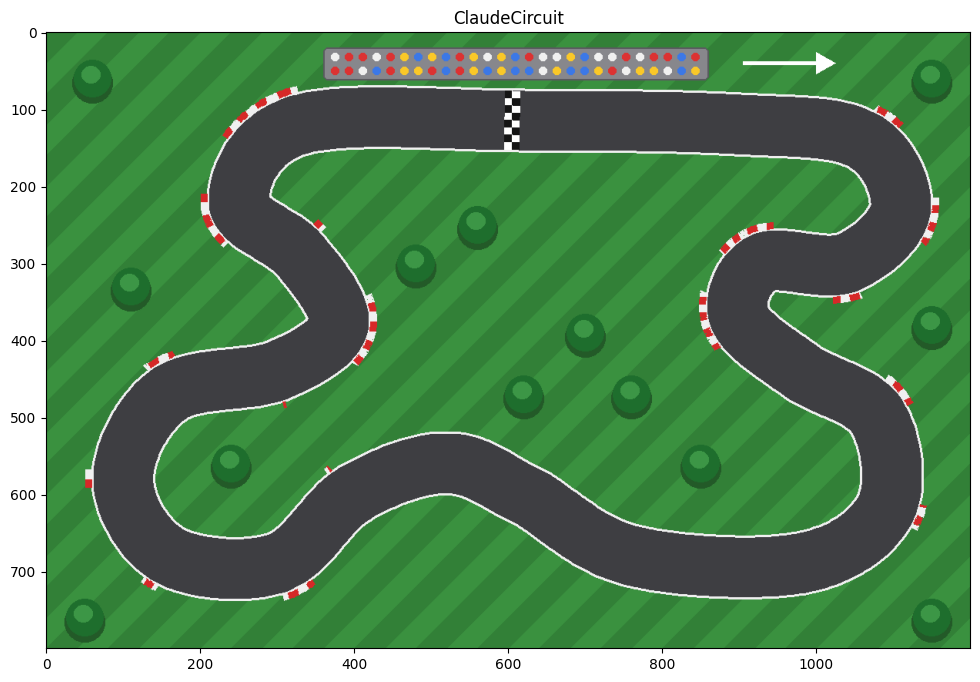

In [6]:
from src.circuit import Circuit

circuit = Circuit(config.CIRCUIT_IMAGE, config.CIRCUIT_MASK)
print("Taille :", circuit.width, "x", circuit.height)

plt.figure(figsize=(12, 8))
plt.imshow(circuit.image)
plt.title("Circuit")
plt.show()

In [3]:
# Tests
assert circuit.is_on_track(*config.START_POSITION), "Le départ doit être sur la route"
assert not circuit.is_on_track(10, 10), "Le coin en haut à gauche est dans l'herbe"
assert not circuit.is_on_track(-50, 5000), "Hors de l'image -> False, sans planter"
assert circuit.crossed_finish_line((600, 115), (610, 115))
assert not circuit.crossed_finish_line((610, 115), (600, 115)), "Mauvais sens !"
print("✅ Étape 1 OK")

✅ Étape 1 OK


## Étape 2 — La physique de la voiture
👉 Code `Car.__init__` et `Car.update` dans `src/car.py`.

Ici pas encore d'IA : on pilote avec une suite de commandes écrite à la main.

Vivante : False | pas : 64 | distance : 388 px


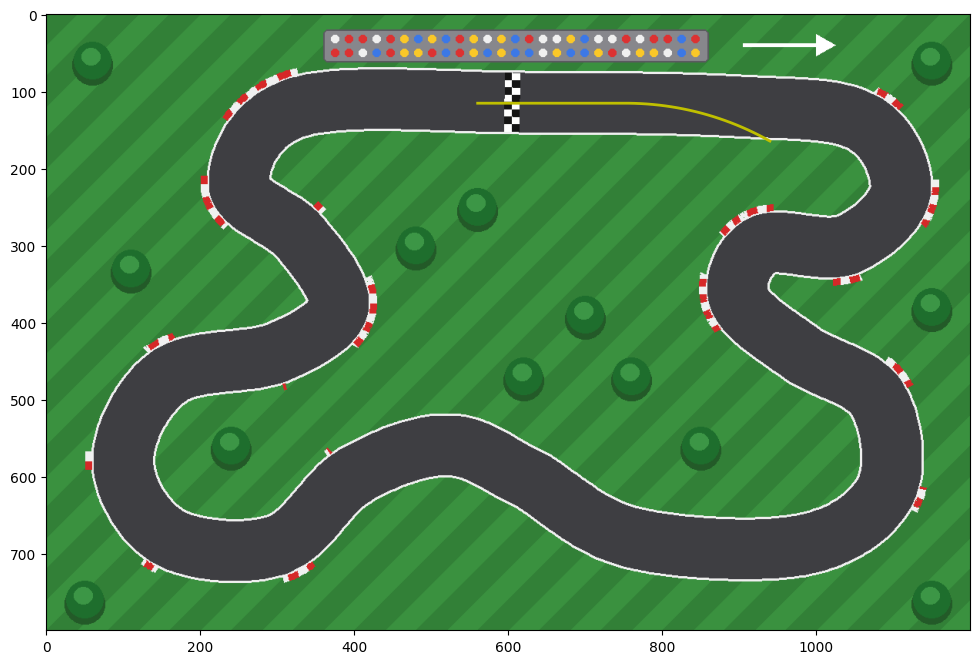

In [11]:
from src.car import Car

car = Car()
positions = [(car.x, car.y)]
for step in range(200):
    steering = 0.0 if step < 40 else 0.3   # tout droit, puis on tourne un peu à droite
    car.update(steering=steering, throttle=1.0, circuit=circuit)
    positions.append((car.x, car.y))
    if not car.alive:
        break

print(f"Vivante : {car.alive} | pas : {car.steps} | distance : {car.distance:.0f} px")
xs, ys = zip(*positions)
plt.figure(figsize=(12, 8))
plt.imshow(circuit.image)
plt.plot(xs, ys, "y-", linewidth=2)
plt.show()

💡 **Défi** : trouve à la main une suite de commandes qui fait passer le premier virage.
Tu vas vite comprendre pourquoi on veut qu'une IA le fasse à notre place !

## Étape 3 — Les capteurs
👉 Code `cast_ray`, `read_sensors` et `get_inputs` dans `src/car.py`.

In [ ]:
car = Car()
distances = car.read_sensors(circuit)
print("Distances :", distances)
print("Entrées du réseau :", car.get_inputs(circuit))

assert len(car.get_inputs(circuit)) == config.N_INPUTS
assert np.all((0 <= car.get_inputs(circuit)) & (car.get_inputs(circuit) <= 1)), "Entrées non normalisées"
# Au départ la voiture est sur une ligne droite : devant, c'est loin ; sur les côtés, c'est proche
assert distances[2] > distances[0] and distances[2] > distances[4]
print("✅ Étape 3 OK")

In [ ]:
# Visualiser les rayons
plt.figure(figsize=(12, 8))
plt.imshow(circuit.image)
for rel_angle, dist in zip(config.SENSOR_ANGLES, distances):
    a = np.radians(car.angle + rel_angle)
    plt.plot([car.x, car.x + np.cos(a) * dist], [car.y, car.y + np.sin(a) * dist], "r-")
plt.plot(car.x, car.y, "yo")
plt.show()

## Étape 4 — Le réseau de neurones
👉 Code `src/neural_network.py`.

In [ ]:
from src.neural_network import NeuralNetwork, relu, tanh

assert np.allclose(relu(np.array([-2.0, 0.0, 3.0])), [0, 0, 3])
assert np.all(np.abs(tanh(np.linspace(-100, 100, 50))) <= 1)

net = NeuralNetwork(config.LAYER_SIZES)
out = net.forward(car.get_inputs(circuit))
print("Sortie [direction, accélération] :", out)
assert out.shape == (config.N_OUTPUTS,)

genome = net.get_genome()
print("Nombre de paramètres :", genome.size)
clone = NeuralNetwork.from_genome(config.LAYER_SIZES, genome)
x = np.random.rand(config.N_INPUTS)
assert np.allclose(net.forward(x), clone.forward(x)), "get_genome / from_genome incohérents"
print("✅ Étape 4 OK")

❓ **Question** : combien de paramètres pour `[6, 8, 2]` ? Calcule-le à la main
avant de regarder le résultat.

## Étape 5 — L'algorithme génétique
👉 Code `src/genetic.py`.

In [ ]:
from src.genetic import crossover, mutate, select_parent, next_generation

a, b = np.zeros(1000), np.ones(1000)
child = crossover(a, b)
print("Part de gènes venant de B :", child.mean())   # ~0.5 attendu

m = mutate(a, rate=0.1, strength=0.5)
print("Part de gènes mutés :", np.mean(m != 0))      # ~0.1 attendu
assert np.all(a == 0), "mutate ne doit pas modifier l'original !"

nets = [NeuralNetwork(config.LAYER_SIZES) for _ in range(10)]
fitnesses = np.arange(10, dtype=float)
new_nets = next_generation(nets, fitnesses, config.LAYER_SIZES, elite_count=2,
                           mutation_rate=0.1, mutation_strength=0.5)
assert len(new_nets) == 10
assert np.allclose(new_nets[0].get_genome(), nets[9].get_genome()), "Le meilleur doit être conservé"
print("✅ Étape 5 OK")

## Étape 6 — Entraînement 🚀
👉 Code `src/simulation.py` (et `compute_fitness` dans `src/genetic.py`).

Commence avec peu de générations pour tester, puis augmente.

In [ ]:
from src.simulation import run_generation, train

best_network, history = train(circuit, n_generations=10, population_size=30)

## Étape 7 — Visualiser les résultats
👉 Code `src/render.py`.

In [12]:
from src.render import plot_history, replay

plot_history(history)

NameError: name 'history' is not defined

In [ ]:
# Ouvre une fenêtre pygame : regarde ta meilleure voiture rouler !
replay(circuit, best_network)

## 🧪 Pour aller plus loin (plus tard)
- Sauvegarder le meilleur génome (`np.save`) et le recharger.
- Changer le nombre de capteurs, la taille du réseau, le taux de mutation… et comparer les courbes.
- Tester le meilleur réseau sur ton `Circuit Paint.png` : généralise-t-il ?
- Remplacer l'algo génétique par de l'apprentissage par renforcement.